# Dynamic panel demonstration: next-day synthetic cases

Region fixed-effects OLS with lagged case counts, target weekday and target month. This is a teaching baseline, not an Arellano-Bond/GMM estimator. Lagged outcomes can cause finite-sample bias in fixed-effects estimation. No causal interpretation is claimed.

Dates are split chronologically into the first two-thirds and last one-third. Training labels must precede the cutoff. The fitted coefficients remain fixed during testing, but each test day uses the observed case history available for that day. This is rolling one-day-ahead evaluation, not a single multi-month forecast.

The input onset histories are retrospective. Report-date delays are not modeled, so these scores demonstrate the synthetic workflow, not real-time performance. Full commuting pressure is missing and is excluded. Static population and commuting attributes are absorbed by region fixed effects. Future target columns are never predictors.


In [4]:
from pathlib import Path
import numpy as np
import pandas as pd

# Place the daily panel CSV in this project folder before running.
PROJECT = Path.cwd()

INPUT = PROJECT / "daily_panel_demo_outputs" / "synthetic_metro_daily_feature_panel.csv"

OUTPUT = PROJECT / "dynamic_panel_demo_outputs"

def run_demo(input_file=INPUT, output_dir=OUTPUT):
    panel = pd.read_csv(input_file, dtype={"state": str, "zcta": str}, parse_dates=["date"])
    assert panel.is_synthetic_demo.astype(str).str.lower().eq("true").all()
    assert not panel.duplicated(["state", "zcta", "date"]).any()
    panel = panel.sort_values(["state", "zcta", "date"]).reset_index(drop=True)
    panel["region"] = panel.state + "_" + panel.zcta
    panel["target_date"] = panel.date + pd.Timedelta(days=1)

    # Split by calendar date, not by row number or random sampling.
    dates = pd.DatetimeIndex(sorted(panel.date.unique()))
    cutoff = dates[len(dates) * 2 // 3]
    numeric = ["cases_today", "cases_lag_1", "cases_lag_7"]
    target = "target_cases_t_plus_1"
    eligible = panel.dropna(subset=numeric + [target]).copy()
    # Training labels must also be strictly before the test cutoff.
    train = eligible.loc[(eligible.date < cutoff) & (eligible.target_date < cutoff)].copy()
    test = eligible.loc[eligible.date >= cutoff].copy()
    assert train.target_date.max() < cutoff <= test.date.min()
    assert set(test.region).issubset(set(train.region))

    # Pooled least squares with region fixed effects and dynamic case terms.
    # Calendar indicators can be evaluated on future dates; no date fixed
    # effects or future actual outcomes are used as predictor columns.
    def make_design(frame):
        cats = pd.DataFrame(index=frame.index)
        cats["region"] = frame.region
        cats["target_weekday"] = frame.target_date.dt.dayofweek.astype(str)
        cats["target_month"] = frame.target_date.dt.month.astype(str)
        dummies = pd.get_dummies(cats, drop_first=True, dtype=float)
        x = pd.concat([frame[numeric].astype(float), dummies], axis=1)
        x.insert(0, "intercept", 1.0)
        return x

    x_train = make_design(train)
    x_test = make_design(test).reindex(columns=x_train.columns, fill_value=0.0)
    y_train = train[target].to_numpy(dtype=float)
    beta, _, rank, _ = np.linalg.lstsq(x_train.to_numpy(), y_train, rcond=None)
    assert rank == x_train.shape[1], "The design matrix is rank deficient."

    def predict(frame, x):
        pred = frame[["state", "zcta", "date", "target_date", target, "cases_today"]].copy()
        pred = pred.rename(columns={target: "actual_cases", "cases_today": "persistence_prediction"})
        pred["panel_prediction_raw"] = x.to_numpy() @ beta
        # Negative predictions are clipped to zero. Keep decimals as estimates.
        pred["panel_prediction"] = pred.panel_prediction_raw.clip(lower=0)
        return pred

    train_pred = predict(train, x_train)
    test_pred = predict(test, x_test)

    def metrics(frame, prediction):
        actual = frame.actual_cases.to_numpy(dtype=float)
        error = frame[prediction].to_numpy(dtype=float) - actual
        denom = ((actual - actual.mean()) ** 2).sum()
        return {"MAE": float(np.abs(error).mean()),
                "RMSE": float(np.sqrt((error ** 2).mean())),
                "R_squared": float(1 - (error ** 2).sum() / denom) if denom else np.nan}

    metric_rows = []
    for split, frame in [("train", train_pred), ("test", test_pred)]:
        for model, column in [("Dynamic panel FE OLS", "panel_prediction"),
                              ("Persistence: tomorrow = today", "persistence_prediction")]:
            metric_rows.append({"split": split, "model": model, "rows": len(frame), **metrics(frame, column)})
    scores = pd.DataFrame(metric_rows)
    region_rows = []
    for (state, zcta), frame in test_pred.groupby(["state", "zcta"]):
        region_rows.append({"state": state, "zcta": zcta, "rows": len(frame), **metrics(frame, "panel_prediction")})
    region_scores = pd.DataFrame(region_rows)
    coefficients = pd.DataFrame({"term": x_train.columns, "coefficient": beta})
    output_dir.mkdir(parents=True, exist_ok=True)
    scores.to_csv(output_dir / "model_metrics.csv", index=False, encoding="utf-8-sig")
    region_scores.to_csv(output_dir / "test_metrics_by_region.csv", index=False, encoding="utf-8-sig")
    test_pred.to_csv(output_dir / "test_predictions.csv", index=False, encoding="utf-8-sig")
    coefficients.to_csv(output_dir / "model_coefficients.csv", index=False, encoding="utf-8-sig")
    print(f"Test forecast dates start: {cutoff.date()}")
    print(f"Training forecast dates: {train.date.min().date()} to {train.date.max().date()}")
    print(f"Test forecast dates: {test.date.min().date()} to {test.date.max().date()}")
    print(f"Training rows: {len(train):,}; test rows: {len(test):,}")
    print(scores.to_string(index=False))
    print(f"Saved to: {output_dir}")
    return scores, test_pred, coefficients, region_scores



In [5]:
scores, predictions, coefficients, region_scores = run_demo()
display(scores.round(4))
display(region_scores.round(4))
display(coefficients.head(4).round(4))


Test forecast dates start: 2022-09-01
Training forecast dates: 2020-01-09 to 2022-08-30
Test forecast dates: 2022-09-01 to 2023-12-30
Training rows: 7,720; test rows: 3,888
split                         model  rows      MAE     RMSE  R_squared
train          Dynamic panel FE OLS  7720 0.859961 1.250906   0.537426
train Persistence: tomorrow = today  7720 0.983031 1.577325   0.264514
 test          Dynamic panel FE OLS  3888 0.933490 1.252465   0.357972
 test Persistence: tomorrow = today  3888 0.997942 1.544604   0.023534
Saved to: C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun\dynamic_panel_demo_outputs


,split,model,rows,MAE,RMSE,R_squared
0,train,Dynamic panel FE OLS,7720,0.8600,1.2509,0.5374
1,train,Persistence: tomorrow = today,7720,0.9830,1.5773,0.2645
2,test,Dynamic panel FE OLS,3888,0.9335,1.2525,0.3580
3,test,Persistence: tomorrow = today,3888,0.9979,1.5446,0.0235


,state,zcta,rows,MAE,RMSE,R_squared
0,NJ,07024,486,0.9976,1.3168,0.3141
1,NJ,07030,486,1.0789,1.4103,0.4142
2,NJ,07054,486,0.8252,1.0493,0.3057
3,NJ,07102,486,0.7850,1.0421,0.1449
4,NJ,07302,486,1.0525,1.3891,0.3067
5,NJ,08540,486,1.1392,1.5361,0.3809
6,NJ,08901,486,0.9663,1.2888,0.2986
7,NJ,08904,486,0.6231,0.8304,-0.1191


,term,coefficient
0,intercept,0.9698
1,cases_today,0.2608
2,cases_lag_1,0.2559
3,cases_lag_7,0.2309


In [6]:
# Show the first 30 test predictions for one region.
example_zcta = predictions.zcta.iloc[0]
example = predictions.loc[predictions.zcta.eq(example_zcta)].head(30)
display(example.round(3))


C:\Users\41240\AppData\Local\Temp\ipykernel_27180\1461300917.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(example.round(3))


,state,zcta,date,target_date,actual_cases,persistence_prediction,panel_prediction_raw,panel_prediction
973,NJ,07024,2022-09-01,2022-09-02,1.0,1,0.970,0.970
974,NJ,07024,2022-09-02,2022-09-03,3.0,1,1.037,1.037
975,NJ,07024,2022-09-03,2022-09-04,0.0,3,1.628,1.628
976,NJ,07024,2022-09-04,2022-09-05,4.0,0,1.474,1.474
977,NJ,07024,2022-09-05,2022-09-06,1.0,4,1.375,1.375
978,NJ,07024,2022-09-06,2022-09-07,1.0,1,1.886,1.886
979,NJ,07024,2022-09-07,2022-09-08,2.0,1,1.117,1.117
980,NJ,07024,2022-09-08,2022-09-09,1.0,2,1.462,1.462
981,NJ,07024,2022-09-09,2022-09-10,0.0,1,1.293,1.293
982,NJ,07024,2022-09-10,2022-09-11,1.0,0,1.307,1.307


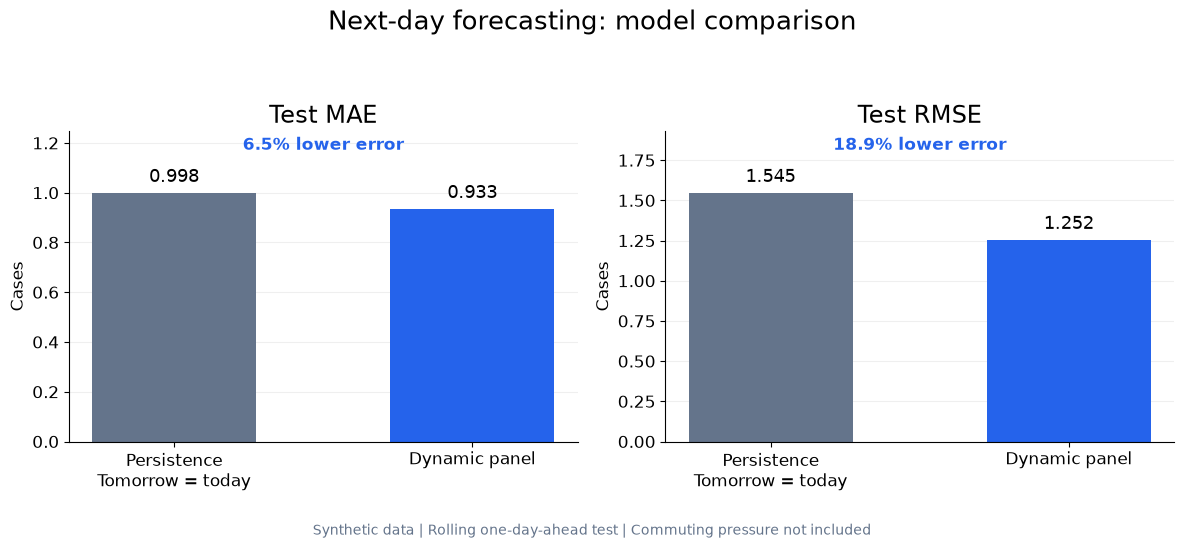

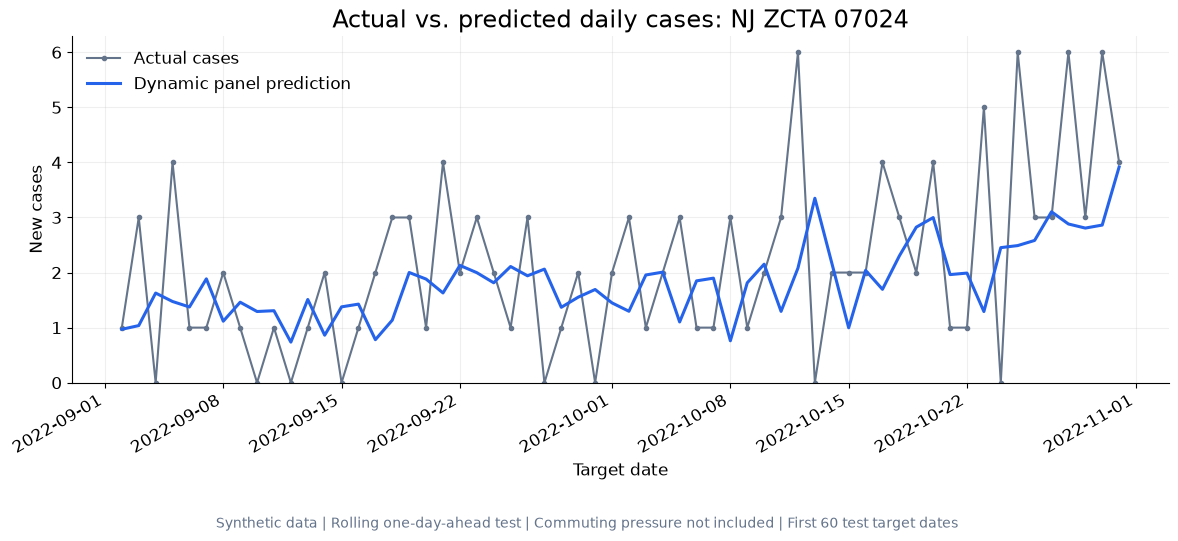

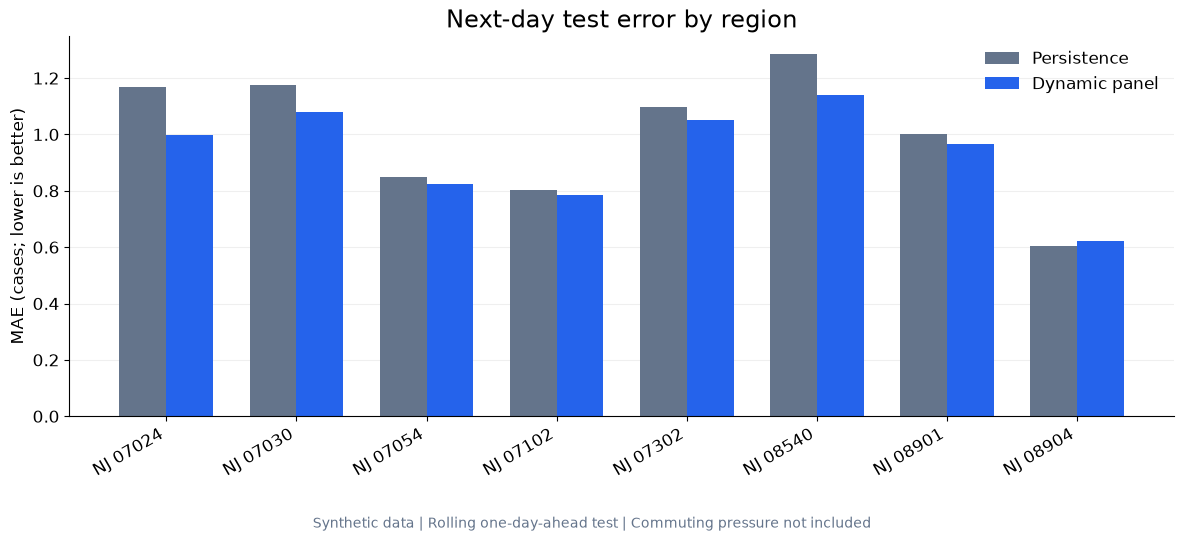

Figures saved to: C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun\dynamic_panel_demo_outputs\figures


In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Save presentation figures in the existing output folder.
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 17,
    "axes.labelsize": 12,
    "figure.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

BLUE = "#2563EB"
ORANGE = "#F59E0B"
GRAY = "#64748B"

NOTE = (
    "Synthetic data | Rolling one-day-ahead test | "
    "Commuting pressure not included"
)

# ------------------------------------------------------------
# Figure 1: Compare test errors against the persistence baseline.
# Lower MAE and RMSE indicate better predictions.
# ------------------------------------------------------------
test_scores = scores.loc[scores["split"].eq("test")].copy()

panel_score = test_scores.loc[
    test_scores["model"].eq("Dynamic panel FE OLS")
].iloc[0]

baseline_score = test_scores.loc[
    test_scores["model"].eq("Persistence: tomorrow = today")
].iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))

for ax, metric in zip(axes, ["MAE", "RMSE"]):
    values = [baseline_score[metric], panel_score[metric]]

    bars = ax.bar(
        ["Persistence\nTomorrow = today", "Dynamic panel"],
        values,
        color=[GRAY, BLUE],
        width=0.55,
    )

    ax.bar_label(bars, fmt="%.3f", padding=5, fontsize=13)
    ax.set_title(f"Test {metric}")
    ax.set_ylabel("Cases")
    ax.set_ylim(0, max(values) * 1.25)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    improvement = (
        (baseline_score[metric] - panel_score[metric])
        / baseline_score[metric] * 100
    )
    ax.text(
        0.5, 0.94,
        f"{improvement:.1f}% lower error",
        transform=ax.transAxes,
        ha="center",
        color=BLUE,
        fontweight="bold",
    )

fig.suptitle("Next-day forecasting: model comparison", fontsize=19)
fig.text(0.5, 0.025, NOTE, ha="center", fontsize=10, color=GRAY)
fig.tight_layout(rect=[0, 0.07, 1, 0.92])
fig.savefig(FIGURES / "01_test_model_comparison.png", dpi=300)
plt.show()


# ------------------------------------------------------------
# Figure 2: Actual vs. predicted cases for one example region.
# Change EXAMPLE_ZCTA to view another region.
# The first 60 target dates are shown.
# ------------------------------------------------------------
EXAMPLE_STATE = "NJ"
EXAMPLE_ZCTA = "07024"

example_plot = (
    predictions.loc[
        predictions["state"].eq(EXAMPLE_STATE)
        & predictions["zcta"].eq(EXAMPLE_ZCTA)
    ]
    .sort_values("target_date")
    .head(60)
)

if example_plot.empty:
    raise ValueError("The selected region is not in the test predictions.")

fig, ax = plt.subplots(figsize=(12, 5.5))

ax.plot(
    example_plot["target_date"],
    example_plot["actual_cases"],
    label="Actual cases",
    color=GRAY,
    marker="o",
    markersize=3,
    linewidth=1.5,
)

ax.plot(
    example_plot["target_date"],
    example_plot["panel_prediction"],
    label="Dynamic panel prediction",
    color=BLUE,
    linewidth=2.2,
)

ax.set_title(
    f"Actual vs. predicted daily cases: "
    f"{EXAMPLE_STATE} ZCTA {EXAMPLE_ZCTA}"
)
ax.set_xlabel("Target date")
ax.set_ylabel("New cases")
ax.set_ylim(bottom=0)
ax.grid(alpha=0.2)
ax.legend(frameon=False)
fig.autofmt_xdate(rotation=30)

fig.text(
    0.5, 0.025,
    NOTE + " | First 60 test target dates",
    ha="center", fontsize=10, color=GRAY,
)
fig.tight_layout(rect=[0, 0.08, 1, 1])
fig.savefig(FIGURES / "02_actual_vs_predicted.png", dpi=300)
plt.show()


# ------------------------------------------------------------
# Figure 3: Test MAE by region, with both models compared.
# ------------------------------------------------------------
region_comparison = predictions.copy()

region_comparison["panel_absolute_error"] = (
    region_comparison["panel_prediction"]
    - region_comparison["actual_cases"]
).abs()

region_comparison["baseline_absolute_error"] = (
    region_comparison["persistence_prediction"]
    - region_comparison["actual_cases"]
).abs()

region_mae = (
    region_comparison
    .groupby(["state", "zcta"])[
        ["panel_absolute_error", "baseline_absolute_error"]
    ]
    .mean()
    .reset_index()
    .sort_values(["state", "zcta"])
)

labels = region_mae["state"] + " " + region_mae["zcta"]
positions = np.arange(len(region_mae))
width = 0.36

fig, ax = plt.subplots(figsize=(12, 5.5))

ax.bar(
    positions - width / 2,
    region_mae["baseline_absolute_error"],
    width,
    label="Persistence",
    color=GRAY,
)

ax.bar(
    positions + width / 2,
    region_mae["panel_absolute_error"],
    width,
    label="Dynamic panel",
    color=BLUE,
)

ax.set_xticks(positions)
ax.set_xticklabels(labels, rotation=30, ha="right")
ax.set_title("Next-day test error by region")
ax.set_ylabel("MAE (cases; lower is better)")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(frameon=False)

fig.text(0.5, 0.025, NOTE, ha="center", fontsize=10, color=GRAY)
fig.tight_layout(rect=[0, 0.08, 1, 1])
fig.savefig(FIGURES / "03_test_error_by_region.png", dpi=300)
plt.show()

print("Figures saved to:", FIGURES.resolve())

In [1]:
import os
print(os.getcwd())

C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun


In [2]:
import os

print("Data:", os.path.exists("../Data"))
print("Cleaning:", os.path.exists("cleaning_outputs"))
print("Population:", os.path.exists("population_outputs"))
print("Daily Panel:", os.path.exists("daily_panel_demo_outputs"))
print("Dynamic Panel:", os.path.exists("dynamic_panel_demo_outputs"))
print("NJNY Commute:", os.path.exists("njny_commute_outputs"))
print("Regional Attributes:", os.path.exists("regional_attributes_outputs"))

Data: True
Cleaning: True
Population: True
Daily Panel: True
Dynamic Panel: True
NJNY Commute: True
Regional Attributes: True


In [3]:
from pathlib import Path

root = Path.cwd()

print("Current folder:", root)
print("New output folder:", root / "dynamic_panel_demo_outputs")
print("Old output folder exists:", (root.parent / "dynamic_panel_demo_outputs").exists())

Current folder: C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun
New output folder: C:\Users\41240\OneDrive\文档\GitHub\practicum-project\Weikun\dynamic_panel_demo_outputs
Old output folder exists: False
